In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import mean_squared_error

train = pd.read_csv(r'C:\Users\vsmk3\ds_first_git\train.csv')
test = pd.read_csv(r'C:\Users\vsmk3\ds_first_git\test.csv')
print(f'Train: {train.shape} | Test: {test.shape}')


Train: (1460, 81) | Test: (1459, 80)


In [5]:
# Keep only numeric columns; exclude Id (row identifier) and SalePrice (target)
all_num = train.select_dtypes(include=['int64','float64']).columns.tolist()
features = [c for c in all_num if c not in ['Id','SalePrice']]

print(f'Number of numerical features (excl. Id & SalePrice): {len(features)}')
print('\nFeatures:')
for i, f in enumerate(features, 1):
    print(f'  {i:2d}. {f}')

Number of numerical features (excl. Id & SalePrice): 36

Features:
   1. MSSubClass
   2. LotFrontage
   3. LotArea
   4. OverallQual
   5. OverallCond
   6. YearBuilt
   7. YearRemodAdd
   8. MasVnrArea
   9. BsmtFinSF1
  10. BsmtFinSF2
  11. BsmtUnfSF
  12. TotalBsmtSF
  13. 1stFlrSF
  14. 2ndFlrSF
  15. LowQualFinSF
  16. GrLivArea
  17. BsmtFullBath
  18. BsmtHalfBath
  19. FullBath
  20. HalfBath
  21. BedroomAbvGr
  22. KitchenAbvGr
  23. TotRmsAbvGrd
  24. Fireplaces
  25. GarageYrBlt
  26. GarageCars
  27. GarageArea
  28. WoodDeckSF
  29. OpenPorchSF
  30. EnclosedPorch
  31. 3SsnPorch
  32. ScreenPorch
  33. PoolArea
  34. MiscVal
  35. MoSold
  36. YrSold


In [6]:
pd.set_option('display.max_rows', None)
df.dtypes

NameError: name 'df' is not defined

Top 5 features by |correlation| with SalePrice:
  OverallQual: 0.7910
  GrLivArea: 0.7086
  GarageCars: 0.6404
  GarageArea: 0.6234
  TotalBsmtSF: 0.6136


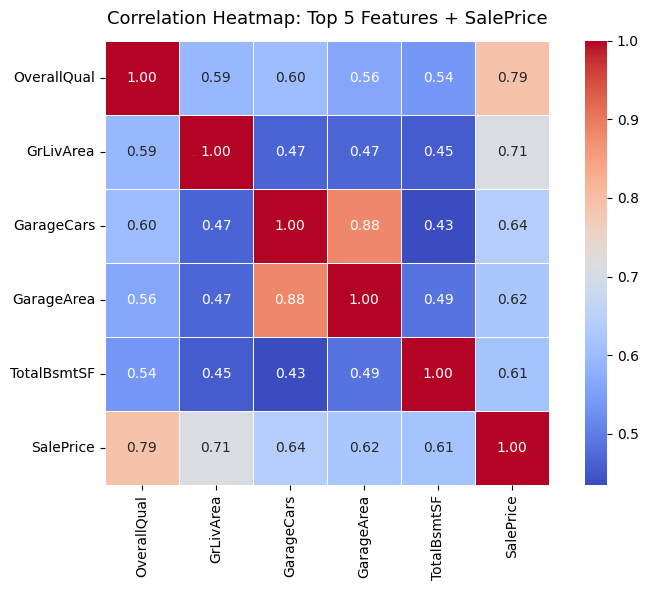

In [7]:
corr_sp = train[features + ['SalePrice']].corr()['SalePrice'].drop('SalePrice')
top5 = corr_sp.abs().sort_values(ascending=False).head(5).index.tolist()

print('Top 5 features by |correlation| with SalePrice:')
for feat in top5:
    print(f'  {feat}: {corr_sp[feat]:.4f}')

fig, ax = plt.subplots(figsize=(8, 6))
cm = train[top5 + ['SalePrice']].corr()
sns.heatmap(cm, annot=True, fmt='.2f', cmap='coolwarm', ax=ax,
            square=True, linewidths=0.5)
ax.set_title('Correlation Heatmap: Top 5 Features + SalePrice', fontsize=13, pad=12)
plt.tight_layout()
plt.show()

In [103]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1379.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,46.549315,567.240411,1057.429452,1162.626712,346.992466,5.844521,1515.463699,0.425342,0.057534,1.565068,0.382877,2.866438,1.046575,6.517808,0.613014,1978.506164,1.767123,472.980137,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,161.319273,441.866955,438.705324,386.587738,436.528436,48.623081,525.480383,0.518911,0.238753,0.550916,0.502885,0.815778,0.220338,1.625393,0.644666,24.689725,0.747315,213.804841,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,0.000000,0.000000,334.000000,0.000000,0.000000,334.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,1900.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,0.000000,223.000000,795.750000,882.000000,0.000000,0.000000,1129.500000,0.000000,0.000000,1.000000,0.000000,2.000000,1.000000,5.000000,0.000000,1961.000000,1.000000,334.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,0.000000,477.500000,991.500000,1087.000000,0.000000,0.000000,1464.000000,0.000000,0.000000,2.000000,0.000000,3.000000,1.000000,6.000000,1.000000,1980.000000,2.000000,480.000000,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,0.000000,808.000000,1298.250000,1391.250000,728.000000,0.000000,1776.750000,1.000000,0.000000,2.000000,1.000000,3.000000,1.000000,7.000000,1.000000,2002.000000,2.000000,576.000000,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1474.000000,2336.000000,6110.000000,4692.000000,2065.000000,572.000000,5642.000000,3.000000,2.000000,3.000000,2.000000,8.000000,3.000000,14.000000,3.000000,2010.000000,4.000000,1418.000000,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [104]:
pd.set_option('display.max_colwidth', None)
# Generate standard object description
desc = df.describe(include=['O'])

# Append a row containing the list of unique entries for each column
desc.loc['unique_entries'] = df[desc.columns].apply(lambda col: col.dropna().unique().tolist())

desc.T

C:\Users\vsmk3\AppData\Local\Temp\ipykernel_20352\42701649.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  desc = df.describe(include=['O'])


,count,unique,top,freq,unique_entries
MSZoning,1460,5,RL,1151,"[RL, RM, C (all), FV, RH]"
Street,1460,2,Pave,1454,"[Pave, Grvl]"
Alley,91,2,Grvl,50,"[Grvl, Pave]"
LotShape,1460,4,Reg,925,"[Reg, IR1, IR2, IR3]"
LandContour,1460,4,Lvl,1311,"[Lvl, Bnk, Low, HLS]"
Utilities,1460,2,AllPub,1459,"[AllPub, NoSeWa]"
LotConfig,1460,5,Inside,1052,"[Inside, FR2, Corner, CulDSac, FR3]"
LandSlope,1460,3,Gtl,1382,"[Gtl, Mod, Sev]"
Neighborhood,1460,25,NAmes,225,"[CollgCr, Veenker, Crawfor, NoRidge, Mitchel, Somerst, NWAmes, OldTown, BrkSide, Sawyer, NridgHt, NAmes, SawyerW, IDOTRR, MeadowV, Edwards, Timber, Gilbert, StoneBr, ClearCr, NPkVill, Blmngtn, BrDale, SWISU, Blueste]"
Condition1,1460,9,Norm,1260,"[Norm, Feedr, PosN, Artery, RRAe, RRNn, RRAn, PosA, RRNe]"


In [105]:
cols_with_missing = df.columns[df.isna().any()]
cols_with_missing

Index(['LotFrontage', 'Alley', 'MasVnrType', 'MasVnrArea', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Electrical', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageQual', 'GarageCond', 'PoolQC', 'Fence', 'MiscFeature'], dtype='str')

In [ ]:
pd.set_option('display.width', 1000)
pd.set_option('display.max_columns', None)
missing_summary = pd.DataFrame({
    'Total_Rows': len(df),
    'Non_Null_Count': df.notna().sum(),
    'Missing_Count': df.isna().sum(),
    'Missing_Percent (%)': (df.isna().sum() / len(df) * 100).round(2),
    'dtype': df.dtypes
})

missing_summary = missing_summary[missing_summary['Missing_Count'] > 0].sort_values(
    by='Missing_Count', ascending=False
)

print(missing_summary)

              Total_Rows  Non_Null_Count  Missing_Count  Missing_Percent (%)    dtype
PoolQC              1460               7           1453                99.52      str
MiscFeature         1460              54           1406                96.30      str
Alley               1460              91           1369                93.77      str
Fence               1460             281           1179                80.75      str
MasVnrType          1460             588            872                59.73      str
FireplaceQu         1460             770            690                47.26      str
LotFrontage         1460            1201            259                17.74  float64
GarageType          1460            1379             81                 5.55      str
GarageYrBlt         1460            1379             81                 5.55  float64
GarageFinish        1460            1379             81                 5.55      str
GarageQual          1460            1379             8

In [107]:
# 1. Identify all columns that have at least one missing value
cols_with_missing = df.columns[df.isna().any()]

# 2. Separate into categorical and numerical column lists
cat_missing = df[cols_with_missing].select_dtypes(include=['object', 'category']).columns.tolist()
df[cat_missing] = df[cat_missing].fillna("None")
num_missing = df[cols_with_missing].select_dtypes(include=['number']).columns.tolist()

print("Categorical with missing values:", cat_missing)
print("Numerical with missing values:", num_missing)

Categorical with missing values: ['Alley', 'MasVnrType', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Electrical', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PoolQC', 'Fence', 'MiscFeature']
Numerical with missing values: ['LotFrontage', 'MasVnrArea', 'GarageYrBlt']


C:\Users\vsmk3\AppData\Local\Temp\ipykernel_20352\795726337.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_missing = df[cols_with_missing].select_dtypes(include=['object', 'category']).columns.tolist()


In [108]:
df['LotFrontage'] = df['LotFrontage'].fillna(df['LotFrontage'].median())

# 2. Impute Electrical with Global Mode ('SBrkr')
df['Electrical'] = df['Electrical'].fillna(df['Electrical'].mode()[0])